In [6]:
#imports
import matplotlib.pyplot as plt
import numpy as np
import pickle

import copy
from pathlib import Path


import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Set random seeds for reproducibility (same as Exercise 2)
np.random.seed(42)
torch.manual_seed(42)

print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.14.1+cu130


In [7]:
#load the data file
with open("delta_data_equal_length.pkl", "rb") as file:
    delta_data = pickle.load(file)

In [8]:
def deltas_to_strokes(trajectory):
    """
    Reconstructs (x, y) strokes from (dx, dy, pen_state).
    
    pen_state = 0: pen is DOWN (this step is part of a stroke -> draw it)
    pen_state = 1: pen is UP   (this step is an air move -> skip it)
    pen_state = 2: END         (stop before applying this step)
    """
    strokes = []
    current_stroke = []
    
    x, y = 0.0, 0.0
    
    for dx, dy, pen_state in trajectory:
        if pen_state == 2:
            break

        prev_x, prev_y = x, y
        x = x + dx
        y = y + dy
        
        if pen_state == 0:
            # Pen is DOWN: include this step in the current stroke
            if not current_stroke:
                # First point of the stroke: include the "from" position too
                current_stroke.append((prev_x, prev_y))
            current_stroke.append((x, y))
            
        else:
            # Pen is UP: flying through the air
            # Save the stroke we were drawing (if any) and reset
            if current_stroke:
                strokes.append(current_stroke)
                current_stroke = []
                
    # Save the last stroke if it exists
    if current_stroke:
        strokes.append(current_stroke)        
    return strokes




Character 'a' has 1 strokes after reconstruction.
Character 'b' has 1 strokes after reconstruction.
Character 'c' has 1 strokes after reconstruction.
Character 'A' has 2 strokes after reconstruction.
Character 'B' has 1 strokes after reconstruction.
Character 'C' has 1 strokes after reconstruction.
Character '1' has 1 strokes after reconstruction.
Character '2' has 1 strokes after reconstruction.
Character '3' has 1 strokes after reconstruction.


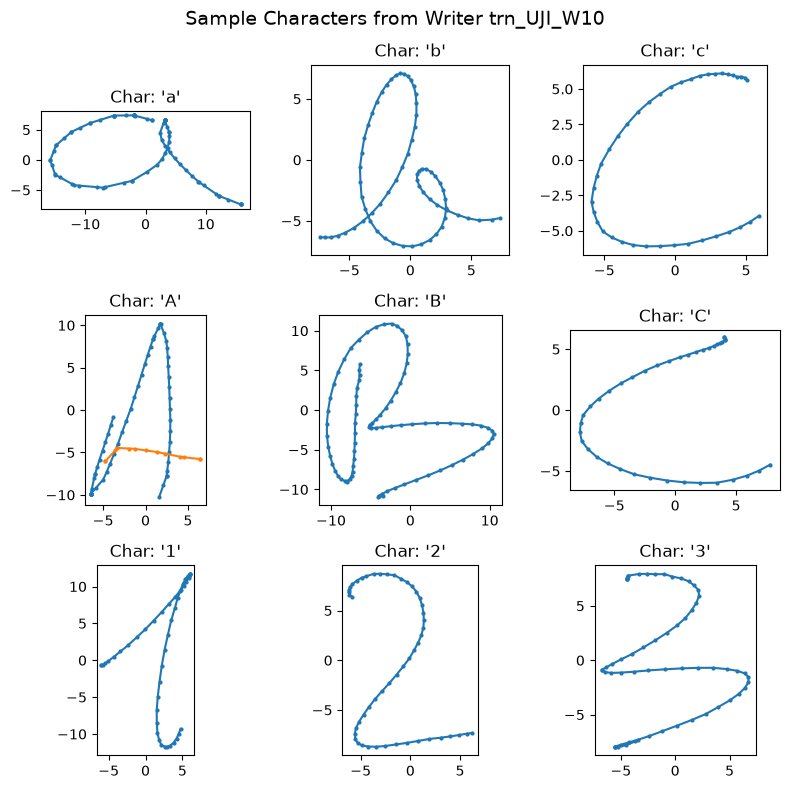

In [9]:
# Plot from delta_data
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']
writer = "trn_UJI_W10"

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    # Get the flat trajectory from delta_data
    trajectory = delta_data[writer][char][0]
    
    # Reconstruct strokes from (dx, dy, pen_state)
    strokes = deltas_to_strokes(trajectory)
    print(f"Character '{char}' has {len(strokes)} strokes after reconstruction.")
    
    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)
        
    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle(f"Sample Characters from Writer {writer}", fontsize=14)
plt.tight_layout()
plt.show()

In [10]:
train_data = {}
val_data = {}
test_data = {}

# 1. Collect all test writer IDs
test_writer_ids = []
for writer_id in delta_data:
    if writer_id.startswith("tst_"):
        test_writer_ids.append(writer_id)

test_writer_ids.sort()

# 2. Split the 20 test writers in half (10 for val, 10 for test)
val_writers = test_writer_ids[:10]
test_writers = test_writer_ids[10:]

# 3. Fill the dictionaries
for writer_id in delta_data:
    if writer_id.startswith("trn_"):
        train_data[writer_id] = delta_data[writer_id]
    elif writer_id in val_writers:
        val_data[writer_id] = delta_data[writer_id]
    elif writer_id in test_writers:
        test_data[writer_id] = delta_data[writer_id]

# 4. Count total samples in each set
def count_samples(dataset):
    total = 0
    for writer_id in dataset:
        for char in dataset[writer_id]:
            total += len(dataset[writer_id][char])
    return total

print(f"Training set:   {len(train_data)} writers | {count_samples(train_data)} samples")
print(f"Validation set: {len(val_data)} writers | {count_samples(val_data)} samples")
print(f"Test set:       {len(test_data)} writers | {count_samples(test_data)} samples")

Training set:   40 writers | 7760 samples
Validation set: 10 writers | 1940 samples
Test set:       10 writers | 1940 samples


Character 'a' has 1 strokes after reconstruction.
Character 'b' has 1 strokes after reconstruction.
Character 'c' has 1 strokes after reconstruction.
Character 'A' has 2 strokes after reconstruction.
Character 'B' has 1 strokes after reconstruction.
Character 'C' has 1 strokes after reconstruction.
Character '1' has 1 strokes after reconstruction.
Character '2' has 1 strokes after reconstruction.
Character '3' has 1 strokes after reconstruction.


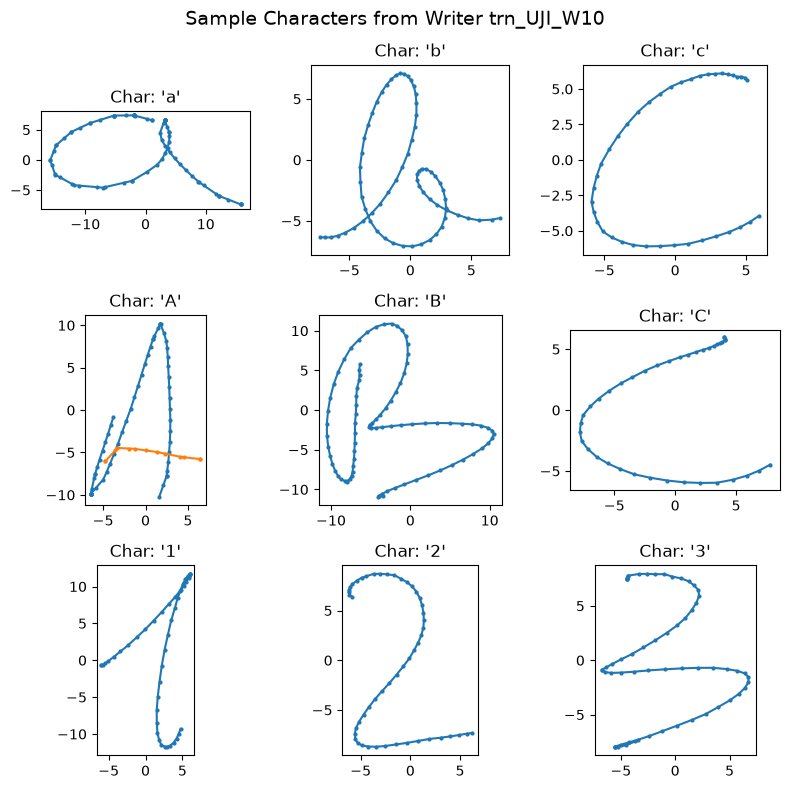

In [11]:
# Plot from delta_data
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']
writer = "trn_UJI_W10"

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    # Get the flat trajectory from delta_data
    trajectory = train_data[writer][char][0]
    
    # Reconstruct strokes from (dx, dy, pen_state)
    strokes = deltas_to_strokes(trajectory)
    print(f"Character '{char}' has {len(strokes)} strokes after reconstruction.")
    
    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)
        
    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle(f"Sample Characters from Writer {writer}", fontsize=14)
plt.tight_layout()
plt.show()

In [7]:
# # Keep originals and add small rotations to training data only.
# ROTATION_ANGLES = (-2.0, 2.0)

# def augment_training_data(data_split, angles):
#     augmented_data = {}

#     for writer_id, characters in data_split.items():
#         augmented_data[writer_id] = {}

#         for char, repetitions in characters.items():
#             augmented_repetitions = []

#             for repetition in repetitions:
#                 trajectory = np.array(
#                     repetition, dtype=np.float32, copy=True
#                 )
#                 augmented_repetitions.append(trajectory)

#                 for angle in angles:
#                     radians = np.deg2rad(angle)
#                     cos_angle = np.cos(radians)
#                     sin_angle = np.sin(radians)

#                     rotation = np.array([
#                         [cos_angle, -sin_angle],
#                         [sin_angle, cos_angle],
#                     ], dtype=np.float32)

#                     rotated = trajectory.copy()

#                     # Rotate movement vectors; preserve pen states.
#                     rotated[:, :2] = trajectory[:, :2] @ rotation.T
#                     augmented_repetitions.append(rotated)

#             augmented_data[writer_id][char] = augmented_repetitions

#     return augmented_data


# # Start from the original samples to avoid accumulating copies on reruns.
# original_train_data = {
#     writer_id: characters
#     for writer_id, characters in delta_data.items()
#     if writer_id.startswith("trn_")
# }

# train_data = augment_training_data(
#     original_train_data, ROTATION_ANGLES
# )

# print(
#     f"Training samples: {count_samples(original_train_data)} originals"
#     f" -> {count_samples(train_data)} after augmentation"
# )
# print(f"Validation samples: {count_samples(val_data)}")
# print(f"Test samples: {count_samples(test_data)}")

In [12]:
# 1. Collect all unique characters and give each one a unique number (0, 1, 2, ...)
all_chars = []
for writer_id in delta_data:
    for char in delta_data[writer_id]:
        if char not in all_chars:
            all_chars.append(char)

#char_to_id = {char: i for i , char in enumerate(all_chars)}
char_to_id = {}
for i in range(len(all_chars)):
    char_to_id[all_chars[i]] = i

num_chars = len(all_chars)

print(f"Total unique characters: {num_chars}")

# 2. Build dataset lists with the shared char_to_id
def build_dataset_lists(data_split):
    c_list = []
    X_list = []
    y_list = []

    for writer_id in data_split:
        for char in data_split[writer_id]:
            c_id = char_to_id[char]  # Uses the shared character ID

            for rep in data_split[writer_id][char]:
                traj = np.array(rep, dtype=np.float32)
                len_traj = len(traj)
                traj = np.array(rep, dtype=np.float32)

                start = np.array([[0.0, 0.0, 1.0]], dtype=np.float32)
                inp = np.concatenate([start, traj[:-1]], axis=0)
                tgt = traj
                c_list.append(c_id)
                X_list.append(inp)
                y_list.append(tgt)

    return c_list, X_list, y_list


c_train, X_train, y_train = build_dataset_lists(train_data)
c_val,   X_val,   y_val   = build_dataset_lists(val_data)
c_test,  X_test,  y_test  = build_dataset_lists(test_data)

Total unique characters: 97


In [13]:
# 1. Find the maximum sequence length across all sets
max_len = 0
for seq in X_train + X_val + X_test:
    if len(seq) > max_len:
        max_len = len(seq)

print("Maximum sequence length:", max_len)


# 2. Simple padding function
def pad_data(c_list, X_list, y_list, max_len):
    total_samples = len(X_list)

    # Create empty arrays filled with zeros
    X_padded = np.zeros((total_samples, max_len, 3), dtype=np.float32)
    y_padded = np.zeros((total_samples, max_len, 3), dtype=np.float32)
    mask = np.zeros((total_samples, max_len), dtype=bool)

    # Fill in the real data
    for i in range(total_samples):
        seq_len = len(X_list[i])

        # Copy original points
        X_padded[i, :seq_len, :] = X_list[i]
        y_padded[i, :seq_len, :] = y_list[i]

        # True for real points, False for padded zeros
        mask[i, :seq_len] = True

    c_array = np.array(c_list, dtype=np.int64)

    return c_array, X_padded, y_padded, mask


# 3. Apply padding to Train, Val, and Test
c_train_pad, X_train_pad, y_train_pad, mask_train = pad_data(c_train, X_train, y_train, max_len)
c_val_pad,   X_val_pad,   y_val_pad,   mask_val   = pad_data(c_val,   X_val,   y_val,   max_len)
c_test_pad,  X_test_pad,  y_test_pad,  mask_test  = pad_data(c_test,  X_test,  y_test,  max_len)

print("Padded X_train shape:", X_train_pad.shape)
print("Mask train shape:    ", mask_train.shape)

Maximum sequence length: 144
Padded X_train shape: (7760, 144, 3)
Mask train shape:     (7760, 144)


In [14]:
# Convert to PyTorch Datasets
train_dataset = TensorDataset(
    torch.tensor(c_train_pad),
    torch.tensor(X_train_pad),
    torch.tensor(y_train_pad),
    torch.tensor(mask_train)
)

val_dataset = TensorDataset(
    torch.tensor(c_val_pad),
    torch.tensor(X_val_pad),
    torch.tensor(y_val_pad),
    torch.tensor(mask_val)
)

test_dataset = TensorDataset(
    torch.tensor(c_test_pad),
    torch.tensor(X_test_pad),
    torch.tensor(y_test_pad),
    torch.tensor(mask_test)
)
train_loader = DataLoader(train_dataset)
val_loader   = DataLoader(val_dataset)
test_loader  = DataLoader(test_dataset)

In [15]:

# # ==============================================================================
# # 1. LSTM MODEL
# # ==============================================================================

# class HandwritingLSTM(nn.Module):

#     def __init__(self, num_chars, hidden_size=32,
#                  num_layers=4, embedding_dim=16):

#         super().__init__()
#         self.char_embedding = nn.Embedding(num_chars, embedding_dim)

#         # LSTM input: dx, dy, pen_state + (character embedding)
#         self.lstm = nn.LSTM(
#             input_size= 3 + embedding_dim,
#             hidden_size=hidden_size,
#             num_layers=num_layers,
#             batch_first=True
#         )

#         # Predict dx and dy
#         self.xy_head = nn.Linear(hidden_size, 2)

#         # Predict binary pen-state logit
#         self.pen_head = nn.Linear(hidden_size, 3)

#     def forward(self, x, c, hidden=None):

#         # x: (batch_size, seq_len, 3)
#         # c: (batch_size,)

#         seq_len = x.shape[1]

#         # Select embedding row using character ID
#         char_emb = self.char_embedding(c.long())

#         # Repeat embedding across all time steps
#         char_emb = char_emb.unsqueeze(1)
#         char_emb = char_emb.expand(-1, seq_len, -1)

#         # Combine trajectory and character information
#         lstm_input = torch.cat(
#             [x, char_emb], dim=-1
#         )

#         # LSTM forward pass
#         output, hidden = self.lstm(lstm_input, hidden)

#         # Coordinate predictions
#         xy_pred = self.xy_head(output)

#         # Pen-state logits
#         pen_logits = self.pen_head(output)

#         return xy_pred, pen_logits, hidden


class HandwritingLSTM(nn.Module):

    def __init__(self, num_chars, hidden_size=128,
                 num_layers=3, embedding_dim=32, dropout_p=0.2):

        super().__init__()
        self.char_embedding = nn.Embedding(num_chars, embedding_dim)
        self.emb_dropout = nn.Dropout(dropout_p * 0.5)  # milder dropout on embeddings

        # 1. Inter-layer dropout inside LSTM
        self.lstm = nn.LSTM(
            input_size=3 + embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout_p if num_layers > 1 else 0.0  # Dropout between LSTM layers
        )

        # 2. Output dropout before prediction heads
        self.out_dropout = nn.Dropout(dropout_p)

        self.xy_head = nn.Linear(hidden_size, 2)
        self.pen_head = nn.Linear(hidden_size, 3)

    def forward(self, x, c, hidden=None):
        seq_len = x.shape[1]

        char_emb = self.char_embedding(c.long())
        char_emb = self.emb_dropout(char_emb)  # Drop out embedding features

        char_emb = char_emb.unsqueeze(1).expand(-1, seq_len, -1)
        lstm_input = torch.cat([x, char_emb], dim=-1)

        output, hidden = self.lstm(lstm_input, hidden)

        # Apply dropout to LSTM outputs before feeding to linear heads
        output = self.out_dropout(output)

        xy_pred = self.xy_head(output)
        pen_logits = self.pen_head(output)

        return xy_pred, pen_logits, hidden

In [24]:

# ==============================================================================
# 2. LOSS FUNCTION AND METRICS
# ==============================================================================

import torch.nn.functional as F

def compute_loss_and_metrics(predictions, targets, mask, coord_std,pen_weight):

    xy_pred, pen_logits, _ = predictions

    # Separate target coordinates and pen states
    xy_target = targets[:, :, :2]
    pen_target = targets[:, :, 2]

    # Pen-state class balancing using inverse weights
    train_pen = train_dataset.tensors[2][:, :, 2].long()
    train_mask = train_dataset.tensors[3].bool()
    class_counts = torch.bincount(train_pen[train_mask], minlength=3).float()
    pen_class_weights = (class_counts.max() / class_counts)**0.5  # Square-root inverse weights    
    #pen_class_weights = ((class_counts.max() / class_counts)).to(device)

    # Ignore padded time steps
    mask = mask.float()
    n_valid = mask.sum().clamp(min=1)

    # ----------------------------------------------------
    # A. Coordinate loss (normalized MSE)
    # ----------------------------------------------------

    # Error relative to the training standard deviation
    xy_error = (xy_pred - xy_target) / coord_std

    # Squared error averaged over x and y
    xy_mse = (xy_error ** 2).mean(dim=-1)

    # Masked coordinate loss
    coord_loss = (xy_mse * mask).sum() / n_valid

    # ----------------------------------------------------
    # B. Pen-state loss (weighted binary cross entropy)
    # ----------------------------------------------------

    pen_logits = pen_logits.squeeze(-1)
  # ----------------------------------------------------
  # Pen-State Cross-Entropy Loss
  # ----------------------------------------------------
    pen_target = pen_target.long().masked_fill(~mask.bool(), 0)
    pen_ce = F.cross_entropy(
        pen_logits.transpose(1, 2),
        pen_target,
        weight=pen_class_weights,
        reduction="none",
    )
    pen_loss = (pen_ce * mask).sum() / n_valid

    loss = coord_loss + pen_weight * pen_loss

    # ----------------------------------------------------
    # C. Total loss
    # ----------------------------------------------------

    loss = coord_loss + pen_weight * pen_loss



    return loss, coord_loss, pen_loss


In [41]:

# ==============================================================================
# 3. TRAINING CONFIGURATION & INITIALIZATION
# ==============================================================================


# Model hyperparameters
LSTM_HIDDEN = 128
LSTM_LAYERS = 5
EMBEDDING_DIM = 64

# Training hyperparameters
BATCH_SIZE = 128
PATIENCE = 15
MIN_IMPROVEMENT = 1e-4
PRINT_EVERY = 1

# Pen-state loss weight
PEN_WEIGHT = 0.4


torch.manual_seed(42)
np.random.seed(42)

# CPU selected because the installed PyTorch CUDA build
# was incompatible with your NVIDIA MX230
device = torch.device("cpu")

print("Using device:", device)

# ----------------------------------------------------
# A. DataLoaders
# ----------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ----------------------------------------------------
# B. Calculate coordinate standard deviations
# ----------------------------------------------------

train_targets = train_dataset.tensors[2]
train_masks = train_dataset.tensors[3].bool()

valid_xy = train_targets[:, :, :2][train_masks]

coord_std = valid_xy.std(
    dim=0, correction=0
).clamp(min=1e-6).to(device)

print("Coordinate standard deviations:", coord_std)

# ----------------------------------------------------
# C. Initialize the LSTM
# ----------------------------------------------------

model = HandwritingLSTM(
    num_chars=num_chars,
    hidden_size=LSTM_HIDDEN,
    num_layers=LSTM_LAYERS,
    embedding_dim=EMBEDDING_DIM
).to(device)

print(model)

n_parameters = sum(
    p.numel() for p in model.parameters()
)

print(f"\nLearnable parameters: {n_parameters:,}")

# ----------------------------------------------------
# E. Initialize training history
# ----------------------------------------------------

metrics = [
    "loss",
    "coord_loss",
    "pen_loss",
]

history = {}

for metric in metrics:
    history["train_" + metric] = []
    history["val_" + metric] = []

# ----------------------------------------------------
# F. Initialize early stopping and checkpoints
# ----------------------------------------------------

best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
best_epoch = -1

stage_boundary_epoch = None


Using device: cpu
Coordinate standard deviations: tensor([0.5373, 0.5024])
HandwritingLSTM(
  (char_embedding): Embedding(97, 64)
  (emb_dropout): Dropout(p=0.1, inplace=False)
  (lstm): LSTM(67, 128, num_layers=5, batch_first=True, dropout=0.2)
  (out_dropout): Dropout(p=0.2, inplace=False)
  (xy_head): Linear(in_features=128, out_features=2, bias=True)
  (pen_head): Linear(in_features=128, out_features=3, bias=True)
)

Learnable parameters: 636,101


In [42]:
@torch.inference_mode()
def generate_trajectory(model, char, char_to_id, max_steps=97):
    """Return an (N, 3) NumPy array of (dx, dy, pen_state).

    Pen states: 0 = draw, 1 = pen up, 2 = end of character.
    """
    if char not in char_to_id:
        raise ValueError(f"Unknown character: {char!r}")
    if max_steps < 1:
        raise ValueError("max_steps must be positive.")

    parameter = next(model.parameters())
    c = torch.tensor(
        [char_to_id[char]], dtype=torch.long, device=parameter.device
    )

    # Same start token used during training.
    x = parameter.new_tensor([[[0.0, 0.0, 1.0]]])
    hidden = None
    trajectory = []

    was_training = model.training
    model.eval()

    try:
        for _ in range(max_steps):
            xy_pred, pen_logits, hidden = model(x, c, hidden)

            pen_state = pen_logits[0, -1].argmax()
            step = torch.cat([
                xy_pred[0, -1],
                pen_state.to(dtype=parameter.dtype).reshape(1),
            ])
            trajectory.append(step)

            if pen_state.item() == 2:
                break

            # Feed the predicted point into the next step.
            x = step.reshape(1, 1, 3)

    finally:
        model.train(was_training)

    return torch.stack(trajectory).cpu().numpy()

Epoch   1 | Train Loss: 1.23857 (Coord: 0.83180, Pen: 1.01693) | Val Loss: 0.75266 (Coord: 0.45354, Pen: 0.74779) | LR: 1.0e-03


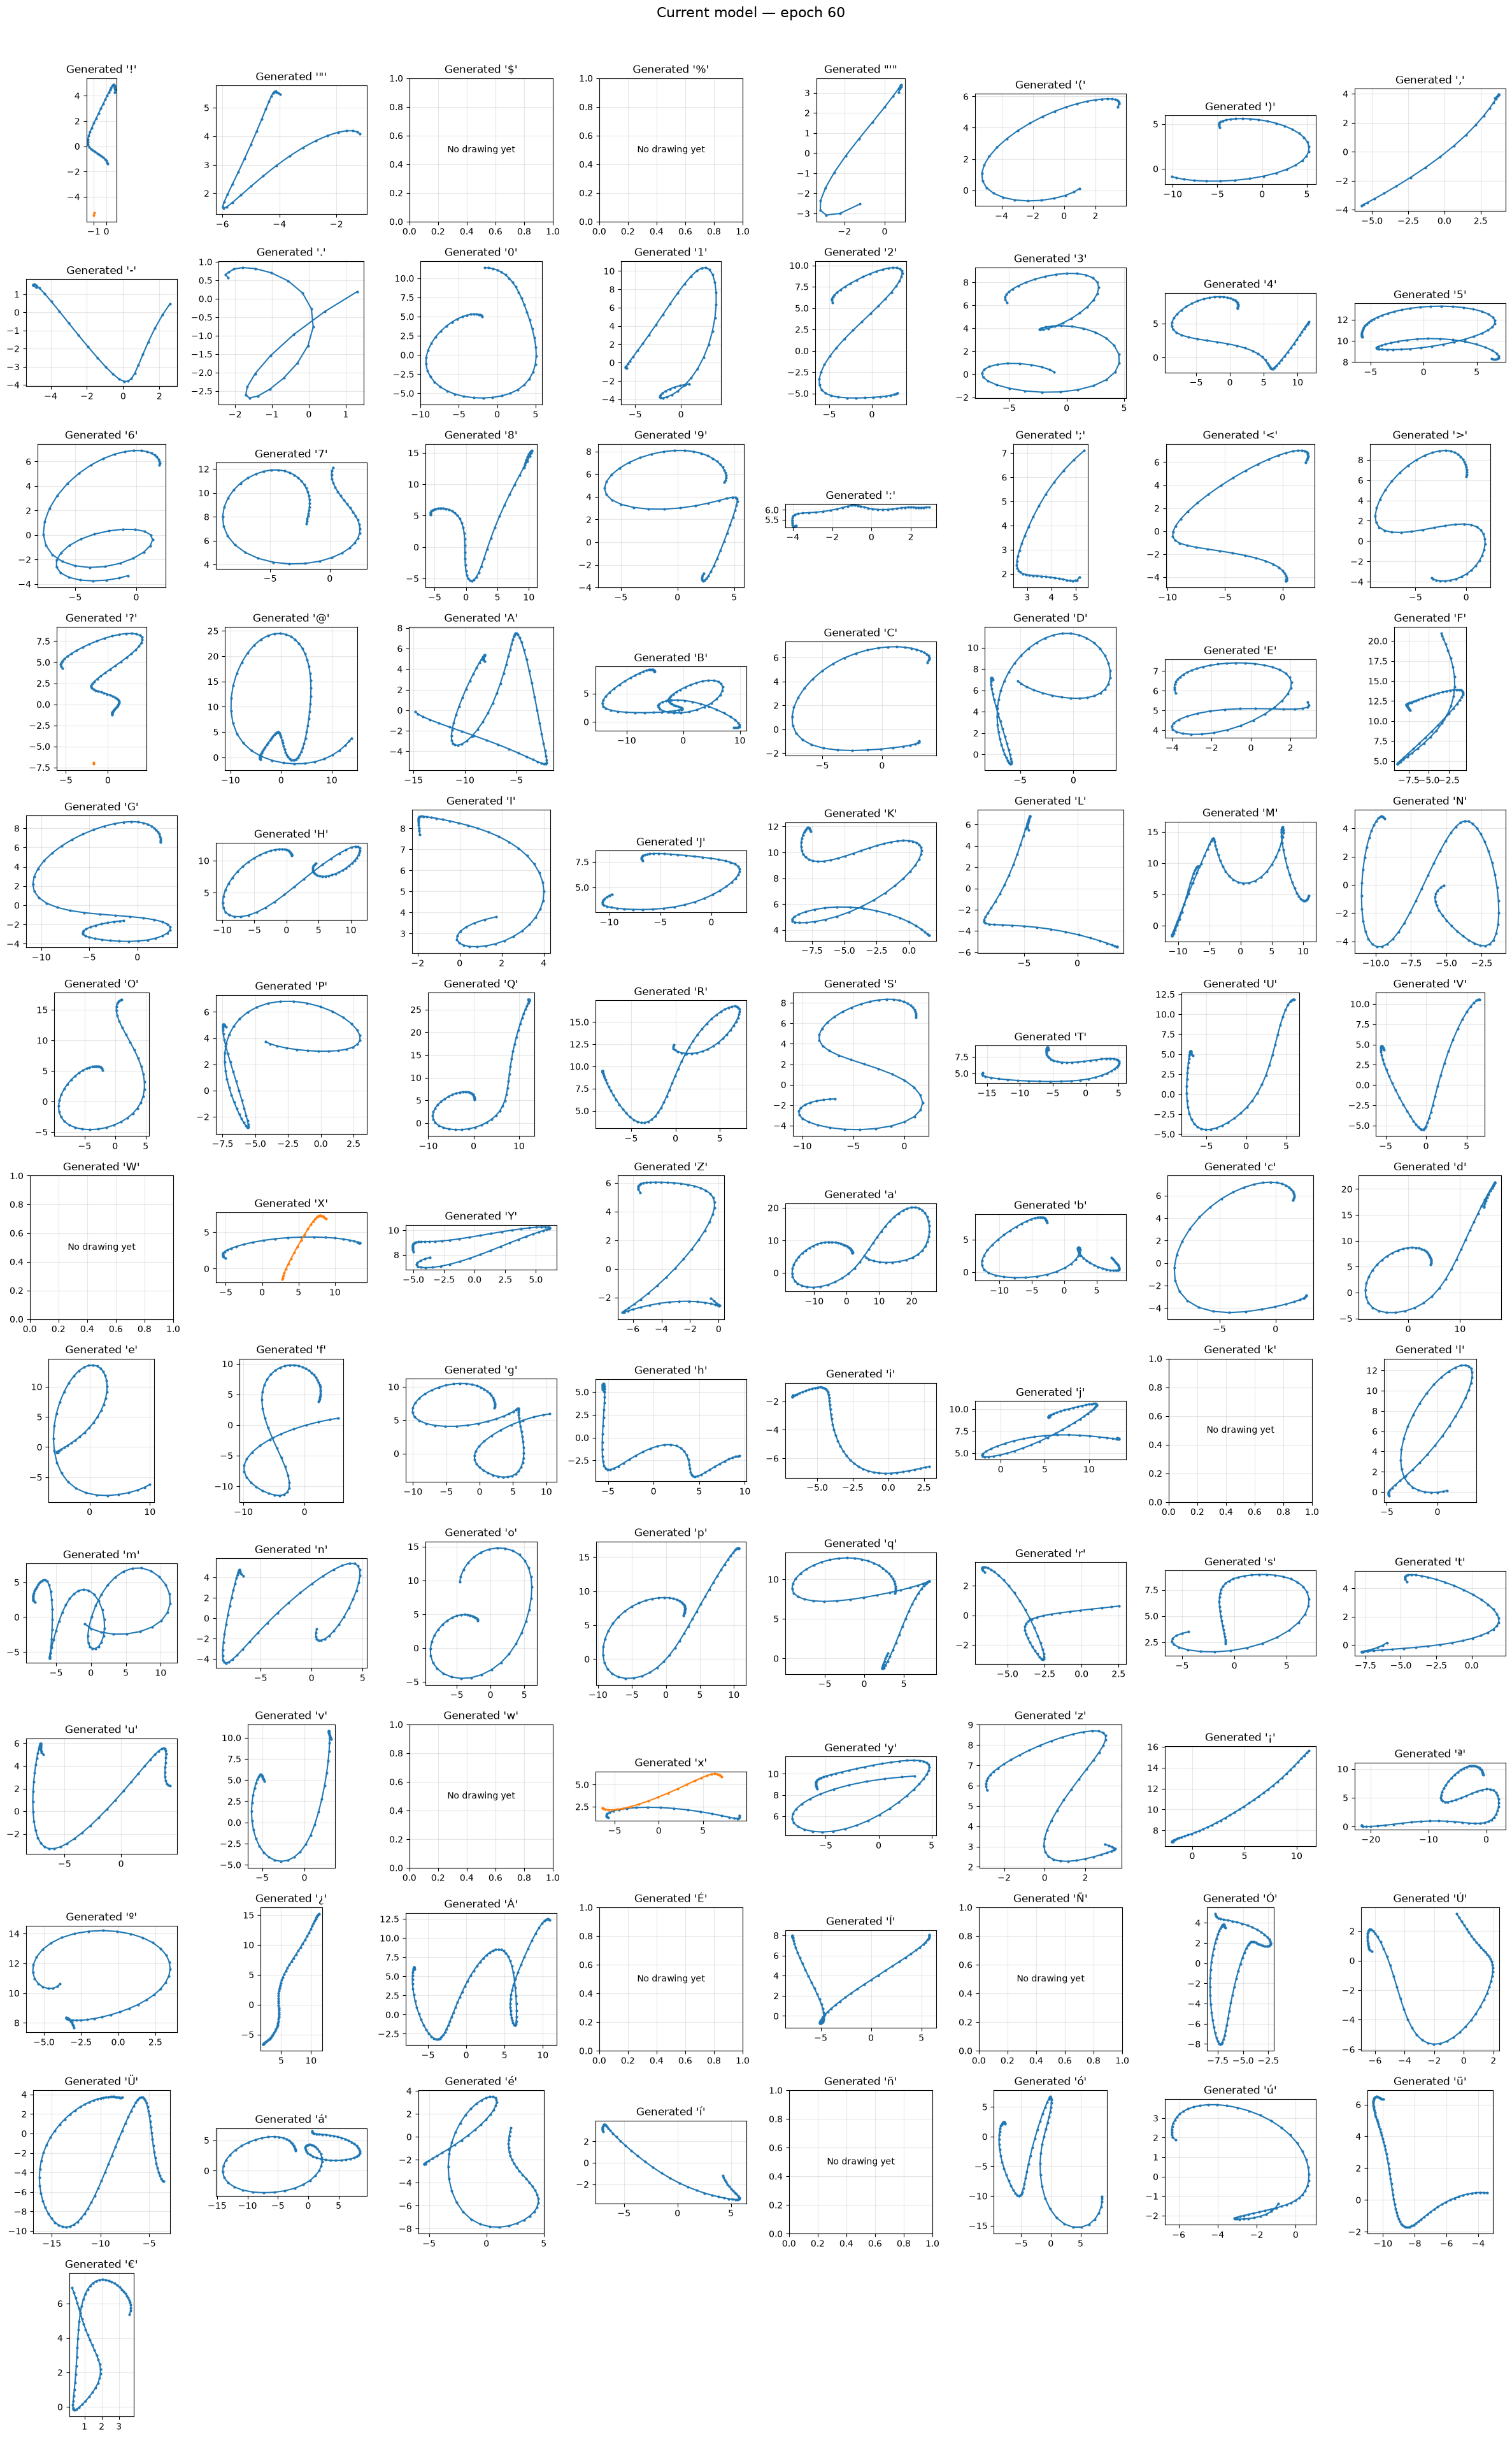

Epoch   2 | Train Loss: 0.57495 (Coord: 0.32723, Pen: 0.61931) | Val Loss: 0.39563 (Coord: 0.20195, Pen: 0.48418) | LR: 1.0e-03
Epoch   3 | Train Loss: 0.41009 (Coord: 0.23078, Pen: 0.44829) | Val Loss: 0.32289 (Coord: 0.16990, Pen: 0.38249) | LR: 1.0e-03
Epoch   4 | Train Loss: 0.34759 (Coord: 0.19854, Pen: 0.37262) | Val Loss: 0.28895 (Coord: 0.15355, Pen: 0.33850) | LR: 1.0e-03
Epoch   5 | Train Loss: 0.31485 (Coord: 0.18090, Pen: 0.33489) | Val Loss: 0.26833 (Coord: 0.14643, Pen: 0.30475) | LR: 1.0e-03
Epoch   6 | Train Loss: 0.29108 (Coord: 0.17300, Pen: 0.29520) | Val Loss: 0.25087 (Coord: 0.14380, Pen: 0.26769) | LR: 1.0e-03
Epoch   7 | Train Loss: 0.26687 (Coord: 0.16621, Pen: 0.25163) | Val Loss: 0.22940 (Coord: 0.13918, Pen: 0.22554) | LR: 1.0e-03
Epoch   8 | Train Loss: 0.25441 (Coord: 0.16082, Pen: 0.23399) | Val Loss: 0.22462 (Coord: 0.13914, Pen: 0.21370) | LR: 1.0e-03
Epoch   9 | Train Loss: 0.24497 (Coord: 0.15705, Pen: 0.21979) | Val Loss: 0.21740 (Coord: 0.13649, Pen:

In [ ]:

# ==============================================================================
# 4. TRAINING LOOP
# ==============================================================================

# ==============================================================================
# LIVE GENERATED-CHARACTER PREVIEW
# ==============================================================================
from IPython.display import display

PREVIEW_EVERY = 5                # 1 = every epoch; 0 = disable previews
PREVIEW_MAX_STEPS = max_len + 1  # Longest full dataset trajectory
PREVIEW_CHARACTERS = None        # All characters, or e.g. ['a', 'b', 'A', '1']
_training_preview = None


def plot_training_samples(model, epoch, characters=None, max_steps=1000,
                          display_handle=None, best=False):
    """Update one character grid while keeping the training loss logs visible."""
    if characters is None:
        characters = sorted({
            char for writer_chars in delta_data.values() for char in writer_chars
        })
    else:
        characters = list(characters)

    if not characters:
        return display_handle

    ncols = min(8, len(characters))
    nrows = (len(characters) + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(3 * ncols, 3 * nrows), squeeze=False
    )

    try:
        for ax, char in zip(axes.flat, characters):
            if char not in char_to_id:
                ax.set_title(f"{char!r}: unavailable in model")
                ax.axis("off")
                continue

            trajectory = generate_trajectory(
                model, char, char_to_id, max_steps=max_steps
            )
            strokes = deltas_to_strokes(trajectory)
            for stroke in strokes:
                xs, ys = zip(*stroke)
                ax.plot(xs, ys, "-o", markersize=2)

            ax.set_title(f"Generated {char!r}")
            ax.set_aspect("equal")
            ax.grid(True, alpha=0.3)
            if not strokes:
                ax.text(0.5, 0.5, "No drawing yet", ha="center", va="center",
                        transform=ax.transAxes)

        for ax in axes.flat[len(characters):]:
            ax.axis("off")

        label = "Best model" if best else "Current model"
        fig.suptitle(f"{label} — epoch {epoch}", fontsize=16)
        fig.tight_layout(rect=(0, 0, 1, 0.97))
        if display_handle is None:
            display_handle = display(fig, display_id=True)
        else:
            display_handle.update(fig)
        return display_handle
    finally:
        plt.close(fig)


def run_epoch(loader, optimizer=None):

    training = optimizer is not None
    model.train(training)

    totals = {
        "loss": 0.0,
        "coord_loss": 0.0,
        "pen_loss": 0.0,
        "pen_acc": 0.0
    }

    total_valid_points = 0
    total_true_up = 0
    total_correct_up = 0

    with torch.set_grad_enabled(training):

        for batch_c, batch_X, batch_y, batch_mask in loader:
            # Move data to device
            batch_c = batch_c.to(device)
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)
            batch_mask = batch_mask.to(device)

            # ----------------------------------------------------
            # A. Forward pass
            # ----------------------------------------------------

            if training:
                optimizer.zero_grad()

            predictions = model(batch_X, batch_c)

            # ----------------------------------------------------
            # B. Calculate loss and metrics
            # ----------------------------------------------------

            loss, coord_l, pen_l = (
                compute_loss_and_metrics(
                    predictions,
                    batch_y,
                    batch_mask,
                    coord_std,
                    PEN_WEIGHT
                )
            )

            # ----------------------------------------------------
            # C. Backpropagation (training only)
            # ----------------------------------------------------

            if training:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=10
                )

                optimizer.step()

            # ----------------------------------------------------
            # D. Accumulate loss and accuracy
            # ----------------------------------------------------

            n = batch_mask.sum().item()
            total_valid_points += n

            totals["loss"] += loss.item() * n
            totals["coord_loss"] += coord_l.item() * n
            totals["pen_loss"] += pen_l.item() * n

            # ----------------------------------------------------
            # E. Calculate pen-up recall counts
            # ----------------------------------------------------

            with torch.no_grad():

                # Predicted class indices: shape [batch_size, seq_len]
                pen_preds = predictions[1].argmax(dim=-1)

                # Class 1 is pen-up
                predicted_up = (pen_preds == 1)

                actual_up = (
                    (batch_y[:, :, 2].long() == 1)
                    & batch_mask.bool()
                )

                total_true_up += actual_up.sum().item()

                total_correct_up += (
                    predicted_up & actual_up
                ).sum().item()

    # ----------------------------------------------------
    # F. Final epoch metrics
    # ----------------------------------------------------

    results = {
        key: value / total_valid_points
        for key, value in totals.items()
    }

    results["coord_rmse"] = np.sqrt(
        results["coord_loss"]
    )

    results["pen_up_recall"] = (
        total_correct_up / total_true_up
        if total_true_up > 0
        else float("nan")
    )

    return results


# ==============================================================================
# MAIN TRAINING PROCESS: TWO STAGES
# ==============================================================================
val_loss=0


# New optimizer, retaining trained model weights
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,             
    weight_decay=1e-4    
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode="min",
    factor=0.5,
    patience=8,        # Reduce LR before early stopping (PATIENCE = 6)
    threshold=MIN_IMPROVEMENT,
    threshold_mode="abs",
    min_lr=1e-5
)


epochs_without_improvement = 0
max_epochs = 1000

try:

    for stage_epoch in range(max_epochs):

        # ----------------------------------------------------
        # A. Training
        # ----------------------------------------------------

        train_results = run_epoch(
            train_loader,
            optimizer=optimizer
        )

        # ----------------------------------------------------
        # B. Validation
        # ----------------------------------------------------

        val_results = run_epoch(
            val_loader,
            optimizer=None
        )
        val_loss = val_results["loss"]
        scheduler.step(val_loss)
        # ----------------------------------------------------
        # C. Record learning curves
        # ----------------------------------------------------

        for metric in metrics:

            history["train_" + metric].append(
                train_results[metric]
            )

            history["val_" + metric].append(
                val_results[metric]
            )

        current_epoch = len(history["train_loss"])

        # ----------------------------------------------------
        # D. Best checkpoint and early stopping
        # ----------------------------------------------------

        val_loss = val_results["loss"]

        if val_loss < best_val_loss - MIN_IMPROVEMENT:

            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = current_epoch - 1

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        # ----------------------------------------------------
        # E. Print training progress
        # ----------------------------------------------------

        if (stage_epoch + 1) % PRINT_EVERY == 0:

            current_lr = optimizer.param_groups[0]["lr"]
            print(
                f"Epoch {current_epoch:3d} | "
                f"Train Loss: {train_results['loss']:.5f} "
                f"(Coord: {train_results['coord_loss']:.5f}, "
                f"Pen: {train_results['pen_loss']:.5f}) | "
                f"Val Loss: {val_results['loss']:.5f} "
                f"(Coord: {val_results['coord_loss']:.5f}, "
                f"Pen: {val_results['pen_loss']:.5f}) | "
                f"LR: {current_lr:.1e}"
            )

        # Update generated characters after epoch 1, periodically, and at stopping.
        if PREVIEW_EVERY > 0 and (
            stage_epoch == 0
            or current_epoch % PREVIEW_EVERY == 0
            or stage_epoch + 1 == max_epochs
            or epochs_without_improvement >= PATIENCE
        ):
            _training_preview = plot_training_samples(
                model,
                epoch=current_epoch,
                characters=PREVIEW_CHARACTERS,
                max_steps=PREVIEW_MAX_STEPS,
                display_handle=_training_preview,
            )

        # ----------------------------------------------------
        # F. Early stopping
        # ----------------------------------------------------

        if epochs_without_improvement >= PATIENCE:

            print(
                f"\nEarly stopping at epoch {current_epoch}."
            )

            break
except KeyboardInterrupt:
    print("\nTraining interrupted by user.")

# ==============================================================================
# RESTORE BEST MODEL
# ==============================================================================

model.load_state_dict(best_state)

print(
    f"\nBest Epoch: {best_epoch + 1} | "
    f"Best Validation Loss: {best_val_loss:.5f}"
)

# Display the best checkpoint after its weights have been restored.
if PREVIEW_EVERY > 0 and best_epoch >= 0:
    _training_preview = plot_training_samples(
        model,
        epoch=best_epoch + 1,
        characters=PREVIEW_CHARACTERS,
        max_steps=PREVIEW_MAX_STEPS,
        display_handle=_training_preview,
        best=True,
    )


In [33]:
model.load_state_dict(best_state)

print(
    f"\nBest Epoch: {best_epoch + 1} | "
    f"Best Validation Loss: {best_val_loss:.5f}"
)



Best Epoch: 128 | Best Validation Loss: 0.11400


### Load the latest saved model (skip training)
Run the imports cell and the cell defining `HandwritingLSTM`, then run the cell below. It selects the most recently modified `handwriting_lstm*.pt` checkpoint and restores the model for inference. You can skip all training cells.

To plot generated characters, also run the `deltas_to_strokes` definition, then the `generate_trajectory` definition and the sample-character plotting cell below.


In [ ]:
# # Load the most recently saved checkpoint without retraining.
# checkpoint_paths = list(Path(".").glob("handwriting_lstm_stage3_best.pt"))
# if not checkpoint_paths:
#     raise FileNotFoundError("No handwriting_lstm*.pt checkpoints found in the current directory.")

# checkpoint_path = max(checkpoint_paths, key=lambda path: path.stat().st_mtime_ns)

# # Use CPU, matching this notebook's training configuration.
# device = torch.device("cpu")
# checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)

# model = HandwritingLSTM(**checkpoint["model_config"]).to(device)
# model.load_state_dict(checkpoint["model_state_dict"])
# model.eval()

# char_to_id = checkpoint["char_to_id"]
# num_chars = checkpoint["model_config"]["num_chars"]
# coord_std = checkpoint["coord_std"].to(device)

# print(f"Loaded: {checkpoint_path.name}")
# print(f"Saved best epoch: {checkpoint['best_epoch']}")
# print(f"Available characters: {len(char_to_id)}")


Loaded: handwriting_lstm_stage3_best.pt
Saved best epoch: 98
Available characters: 97


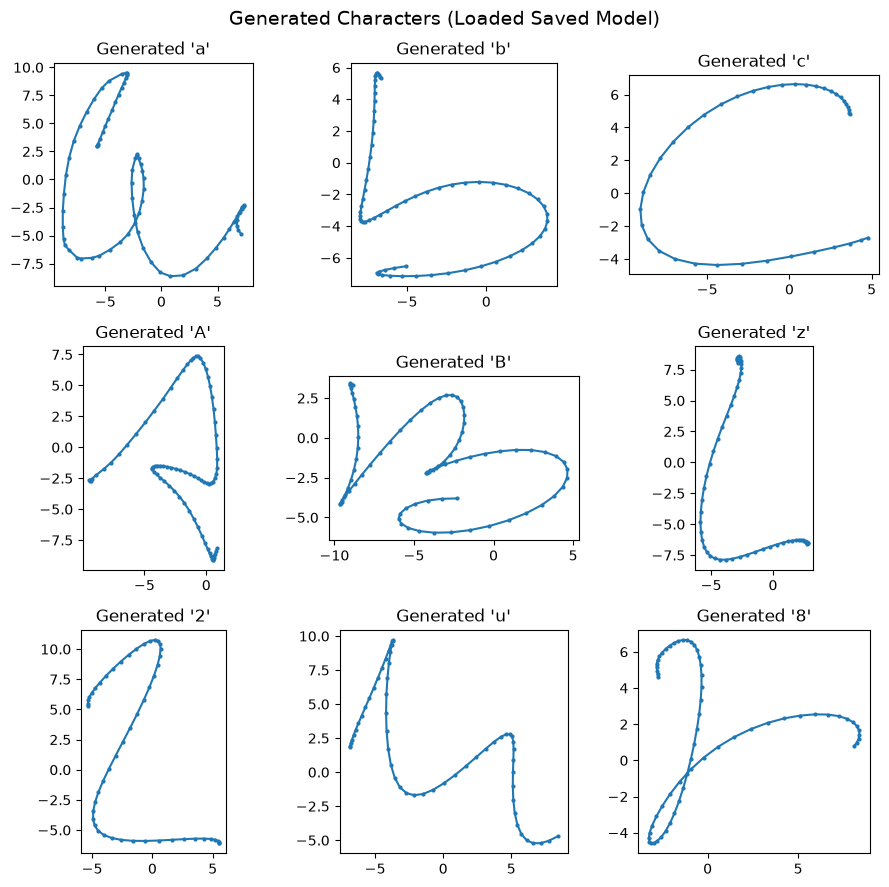

In [36]:
# ==============================================================================
# VISUALIZE: GENERATE SAMPLE CHARACTERS WITH BEST MODEL
# ==============================================================================

sample_chars = ['a', 'b', 'c', 'A', 'B', 'z', '2', 'u', '8']
fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for ax, char in zip(axes.flat, sample_chars):
    if char in char_to_id:
        gen_trajectory = generate_trajectory(model, char, char_to_id, max_steps=500)
        strokes = deltas_to_strokes(gen_trajectory)
        for stroke in strokes:
            xs = [p[0] for p in stroke]
            ys = [p[1] for p in stroke]
            ax.plot(xs, ys, "-o", markersize=2)
        ax.set_aspect("equal")
        ax.set_title(f"Generated '{char}'")
    else:
        ax.axis("off")

plt.suptitle("Generated Characters (Loaded Saved Model)", fontsize=14)
plt.tight_layout()
plt.show()

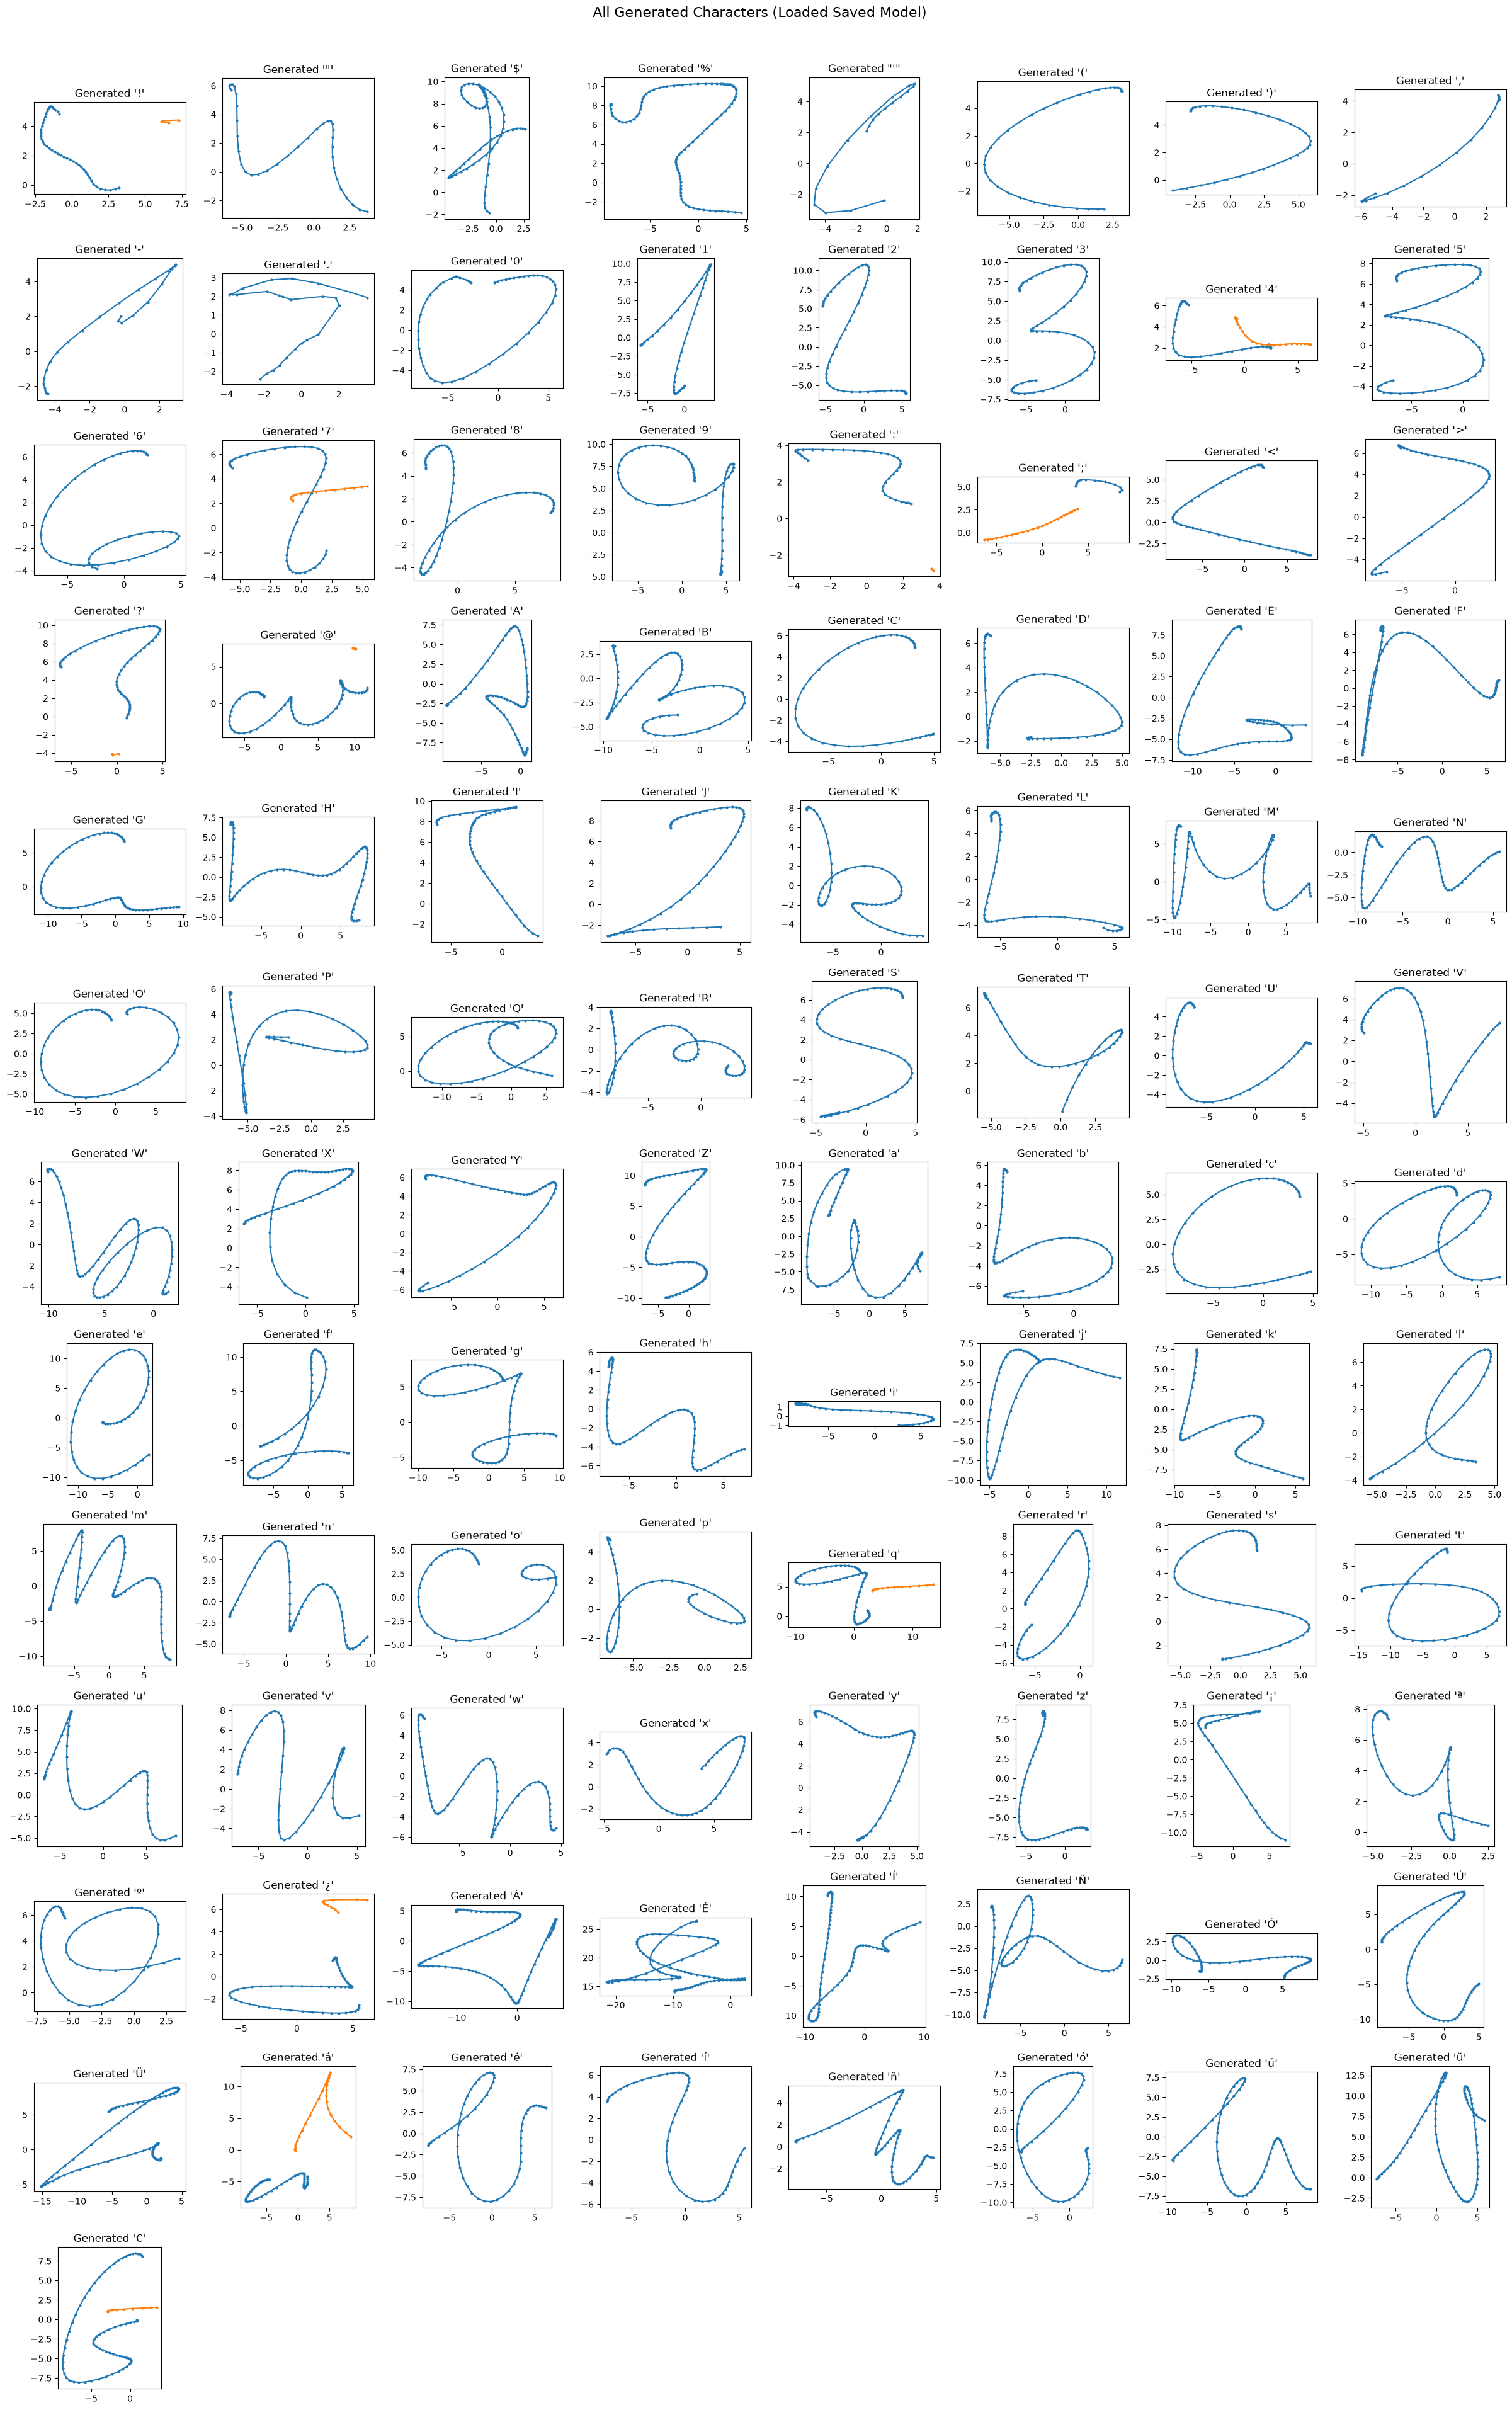

In [37]:
# ==============================================================================
# VISUALIZE: GENERATE EVERY CHARACTER IN DELTA_DATA WITH BEST MODEL
# ==============================================================================

# Collect unique characters across all writers.
generated_chars = sorted({
    char
    for writer_chars in delta_data.values()
    for char in writer_chars
})
if not generated_chars:
    raise ValueError("delta_data contains no characters to plot.")

ncols = min(8, len(generated_chars))
nrows = (len(generated_chars) + ncols - 1) // ncols
fig, axes = plt.subplots(
    nrows, ncols, figsize=(3 * ncols, 3 * nrows), squeeze=False
)

for ax, char in zip(axes.flat, generated_chars):
    if char in char_to_id:
        gen_trajectory = generate_trajectory(model, char, char_to_id, max_steps=1000)
        strokes = deltas_to_strokes(gen_trajectory)
        for stroke in strokes:
            xs = [p[0] for p in stroke]
            ys = [p[1] for p in stroke]
            ax.plot(xs, ys, "-o", markersize=2)
        ax.set_aspect("equal")
        ax.set_title(f"Generated {char!r}")
    else:
        ax.set_title(f"{char!r}: unavailable in saved model")
        ax.axis("off")

# Hide unused grid positions.
for ax in axes.flat[len(generated_chars):]:
    ax.axis("off")

fig.suptitle("All Generated Characters (Loaded Saved Model)", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()
